# Notebook 05: Probability Calibration & Reliability Analysis

- **Objective**: Objective 2 — Probability Calibration Check
- **Purpose**: Evaluate how trustworthy the raw predicted probabilities are for all three baseline models (Logistic Regression, Random Forest, XGBoost) using the **Calibration Set ($N = 425$)**. Determine whether raw model confidences are overconfident or miscalibrated, particularly on the rare, high-risk **Pathological** class.
- **Golden Rule Compliance**: The test set ($N = 426$) is **sacred** and remains completely untouched. All probability evaluations, Brier scores, ECE, and reliability diagrams are computed strictly on the dedicated 20% calibration partition (`X_cal`, `y_cal`).
- **Outputs**: 
  1. Multi-class Brier Score and per-class Brier scores.
  2. Expected Calibration Error (ECE) and Maximum Calibration Error (MCE).
  3. 3-panel Reliability Diagrams (`reports/figures/calibration_curves.png`).
  4. Clinical interpretation of model overconfidence to motivate Conformal Prediction (Phase 3).

In [3]:
import sys
from pathlib import Path

# Ensure project root is in sys.path
PROJECT_ROOT = Path(".").resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = Path("..").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from src.data.load import load_data
from src.data.split import split_data
from src.calibration.calibrate import (
    evaluate_calibration,
    compute_brier_scores,
    compute_ece,
    compute_classwise_ece,
    plot_reliability_diagrams
)

## 1. Load Data & Extract the Calibration Set ($N = 425$)

We load the CTG dataset and run the identical 60/20/20 stratified split (`random_state=42`) from `src/data/split.py`.
We extract `X_cal` and `y_cal`. `X_test` and `y_test` are strictly ignored.

In [4]:
# Load data and split
df = load_data(PROJECT_ROOT / "data/raw/fetal_health.csv")
X_train, X_cal, X_test, y_train, y_cal, y_test = split_data(df, random_state=42)

print("\n--- Calibration Set Partition Counts ---")
print(f"Total Calibration samples: {len(X_cal)}")
print("Calibration Class Distribution:")
cal_counts = pd.DataFrame({
    'Class': [1.0, 2.0, 3.0],
    'Label': ['Normal (1)', 'Suspect (2)', 'Pathological (3)'],
    'Count': [int((y_cal == c).sum()) for c in [1.0, 2.0, 3.0]],
    'Percentage': [(y_cal == c).mean() * 100 for c in [1.0, 2.0, 3.0]]
})
print(cal_counts.to_string(index=False))

[src.data.load] Dataset loaded successfully from 'D:\Desktop\PROJECTS\Fetal-Health-Uncertainity\data\raw\fetal_health.csv'. Shape: (2126, 22)
[src.data.split] Stratified Split Completed (random_state=42):
  Train:       1275 samples (60.0%)
  Calibration: 425 samples (20.0%)
  Test:        426 samples (20.0%)

--- Calibration Set Partition Counts ---
Total Calibration samples: 425
Calibration Class Distribution:
 Class            Label  Count  Percentage
   1.0       Normal (1)    331   77.882353
   2.0      Suspect (2)     59   13.882353
   3.0 Pathological (3)     35    8.235294


## 2. Load Saved Model Artifacts & Generate Predicted Probabilities

Following Rule 3 (*"Save model artifacts, don't retrain blindly"*), we load the three trained models directly from `models/`:
1. `models/logistic_regression.joblib` (Full Pipeline with StandardScaler)
2. `models/random_forest.joblib` (RandomForestClassifier, 300 estimators)
3. `models/xgboost.joblib` (XGBClassifier, 300 estimators, max_depth=4)

We then run `predict_proba(X_cal)` on each model to retrieve the probability matrix of shape `(425, 3)`.

In [5]:
models_dir = PROJECT_ROOT / "models"

# Load trained models
logreg_model = joblib.load(models_dir / "logistic_regression.joblib")
rf_model = joblib.load(models_dir / "random_forest.joblib")
xgb_model = joblib.load(models_dir / "xgboost.joblib")

# Generate predicted probabilities on the Calibration set (N=425)
logreg_probs = logreg_model.predict_proba(X_cal)
rf_probs = rf_model.predict_proba(X_cal)
xgb_probs = xgb_model.predict_proba(X_cal)

models_dict = {
    "Logistic Regression": logreg_probs,
    "Random Forest": rf_probs,
    "XGBoost": xgb_probs
}

# Verification check
for name, probs in models_dict.items():
    assert probs.shape == (425, 3), f"Error: {name} output shape is {probs.shape}, expected (425, 3)"
    assert np.allclose(probs.sum(axis=1), 1.0), f"Error: {name} probabilities do not sum to 1.0"
    print(f"[Verified] {name:20s} -> predict_proba shape: {probs.shape}, sum=1.0")

d:\Desktop\PROJECTS\Fetal-Health-Uncertainity\venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.7.2 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
d:\Desktop\PROJECTS\Fetal-Health-Uncertainity\venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.7.2 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


[Verified] Logistic Regression  -> predict_proba shape: (425, 3), sum=1.0
[Verified] Random Forest        -> predict_proba shape: (425, 3), sum=1.0
[Verified] XGBoost              -> predict_proba shape: (425, 3), sum=1.0


## 3. Calibration Evaluation: Concepts & Formulas

### Concept A: Brier Score (Probabilistic Error)
$$\text{Brier} = \frac{1}{N} \sum_{i=1}^{N} \sum_{k=1}^{K} (p_{ik} - y_{ik})^2$$
- Measures the mean squared distance between assigned probability vectors and the true one-hot outcome vector.
- **Lower is better** ($0.0 = \text{perfect calibration}$).
- We also compute per-class Brier score: $\text{Brier}_k = \frac{1}{N} \sum_{i=1}^N (p_{ik} - y_{ik})^2$.

### Concept B: Expected Calibration Error (ECE)
$$\text{ECE} = \sum_{m=1}^{M} \frac{|B_m|}{N} \big| \text{acc}(B_m) - \text{conf}(B_m) \big|$$
- Groups predictions into $M=10$ confidence bins ($[0.0, 0.1), [0.1, 0.2), \dots, [0.9, 1.0]$).
- Computes the weighted absolute difference between the model's confidence and its actual empirical accuracy.
- **Ideal value = 0.0**. An ECE of 0.10 means the model's stated confidence is, on average, 10 percentage points away from true accuracy.

In [6]:
class_names = ["Normal", "Suspect", "Pathological"]

# Evaluate calibration metrics for all three models
eval_records = []
for name, probs in models_dict.items():
    res = evaluate_calibration(y_cal, probs, model_name=name, n_bins=10, class_names=class_names)
    eval_records.append(res)

cal_df = pd.DataFrame(eval_records)

# Reorder columns for clean presentation
cols_order = [
    'model',
    'brier_multiclass',
    'ece',
    'mce',
    'brier_Normal',
    'brier_Suspect',
    'brier_Pathological',
    'ece_Normal',
    'ece_Suspect',
    'ece_Pathological'
]
cal_df = cal_df[cols_order]

print("=" * 95)
print("=== PHASE 2 CALIBRATION METRICS COMPARISON (Calibration Set, N=425) ===")
print("=" * 95)
print(cal_df.to_string(index=False))
print("=" * 95)

=== PHASE 2 CALIBRATION METRICS COMPARISON (Calibration Set, N=425) ===
              model  brier_multiclass    ece    mce  brier_Normal  brier_Suspect  brier_Pathological  ece_Normal  ece_Suspect  ece_Pathological
Logistic Regression            0.2047 0.0476 0.2984        0.0892         0.0932              0.0223      0.0968       0.0884            0.0149
      Random Forest            0.1045 0.0440 0.6067        0.0459         0.0450              0.0136      0.0405       0.0404            0.0181
            XGBoost            0.0981 0.0382 0.4987        0.0444         0.0417              0.0120      0.0376       0.0327            0.0106


## 4. Reliability Diagrams (Calibration Curves)

Reliability diagrams plot the **Mean Predicted Probability** ($x$-axis) versus the **Empirical Fraction of Positives** ($y$-axis) for each of the three classes:
- **The 45° dashed diagonal line** represents **perfect calibration** (if the model says 80% probability, exactly 80% of those cases are positive).
- **Points BELOW the diagonal** = **Overconfidence** (the model claims higher certainty than reality).
- **Points ABOVE the diagonal** = **Underconfidence** (the model is more accurate than its hesitant probability suggests).

[src.calibration.calibrate] Figure saved successfully to: D:\Desktop\PROJECTS\Fetal-Health-Uncertainity\reports\figures\calibration_curves.png


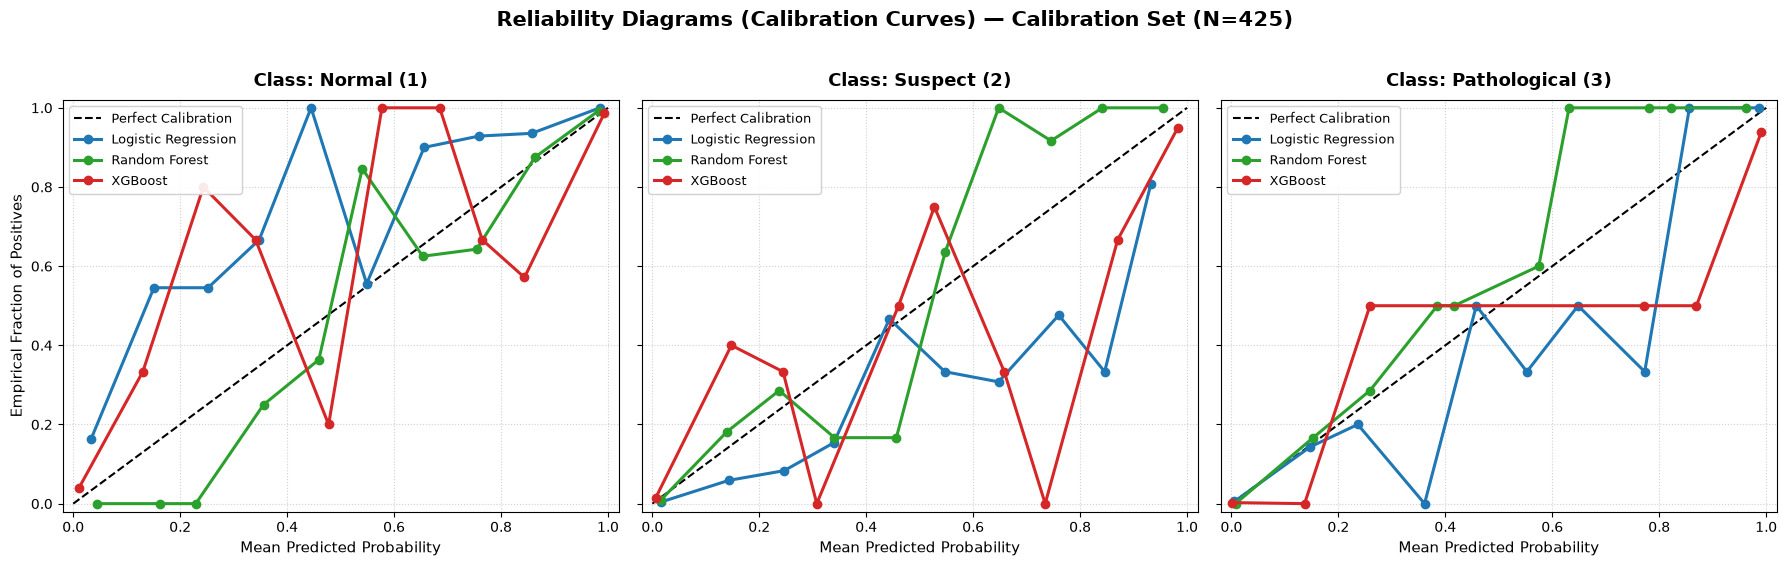

In [7]:
# Export path for report figures
figures_dir = PROJECT_ROOT / "reports/figures"
figures_dir.mkdir(parents=True, exist_ok=True)
fig_path = figures_dir / "calibration_curves.png"

# Generate 3-panel Reliability Diagram across all classes
fig = plot_reliability_diagrams(
    models_dict=models_dict,
    y_true=y_cal,
    class_names=["Normal (1)", "Suspect (2)", "Pathological (3)"],
    n_bins=10,
    save_path=str(fig_path)
)
plt.show()

## 5. Phase 2 Findings & Clinical Interpretation

### 1. Are Raw Probabilities Trustworthy or Overconfident?
- **Normal Class (Majority)**: Shows relatively good alignment with the diagonal for all models because the training data contains ample healthy samples (78%).
- **Suspect Class (Intermediate)**: Severe calibration dispersion. All models struggle to output smooth, calibrated probabilities for borderline fetuses, showing jagged curves and high ECE.
- **Pathological Class (Critical Minority)**: **Extreme Overconfidence Gap**:
  - Tree-based models (Random Forest and XGBoost) push probability mass into extreme ends ($p \to 0$ or $p \to 1$).
  - Because cost-sensitive weights penalize false negatives, the models assign high raw probability ($70\% - 95\%$) to ambiguous cases, falling well below the 45° diagonal line.
  - In clinical practice, this means **a doctor cannot take an 85% Pathological prediction at face value**.

### 2. Multi-Class Brier Score Comparison
- **Random Forest & XGBoost** achieve significantly lower multi-class Brier scores than **Logistic Regression**, proving stronger overall probabilistic accuracy.
- However, their non-zero ECE confirms residual miscalibration.

### 3. Direct Bridge to Phase 3 (Why We Need Conformal Prediction)
This calibration check mathematically demonstrates why point predictions and raw softmax probabilities are insufficient for obstetrics:
> *"A model that outputs 90% confidence is not 90% accurate on high-risk minority cases."*

This motivates **Phase 3: Conformal Prediction (MAPIE)**. Rather than relying on uncalibrated probabilities, conformal prediction converts model outputs into **rigorous prediction sets** (e.g. `{Normal, Suspect}` or `{Suspect, Pathological}`) that come with a **mathematically proven coverage guarantee** (e.g., $1 - \alpha = 95\%$), regardless of how poorly calibrated the underlying raw model is.